<a href="https://colab.research.google.com/github/evgeny-kolonsky/Lab3/blob/main/sound/Lab3_Sound_ek.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab3 Sound waves

Evgeny Kolonsky, Nov 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 6.0 Freq Response

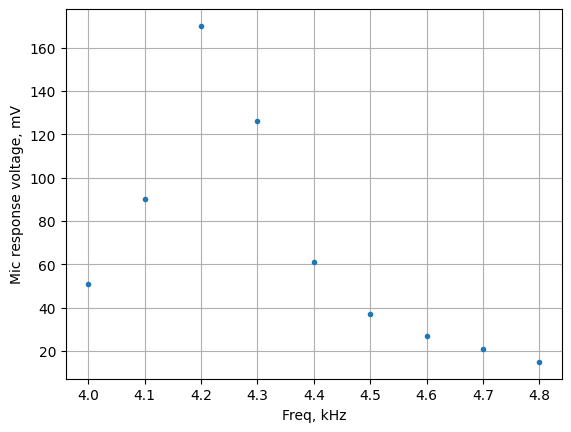

In [2]:
# at minimal distance
# Vpp = 1 V
data = '''
# f/kHz Vmc/mV(AC)
4.0 51
4.1 90
4.2 170
4.3 126
4.4 61
4.5 37
4.6 27
4.7 21
4.8 15
'''
f, V = np.genfromtxt(data.splitlines()).T
plt.plot(f, V, '.')
plt.xlabel('Freq, kHz')
plt.ylabel('Mic response voltage, mV')
plt.grid()

**Conclusion**: working frequency 4.2 kHz

# 6.1 Phase response

at freq 4.2 kHz

Wavelength 9.0 cm at freq 4200 Hz leads wave velocity 377 m/c


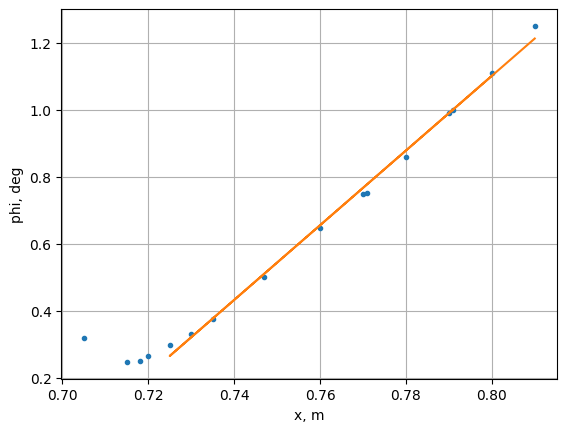

In [3]:
data = '''
# x/cm Vmic/mV phi/deg
81.0 6.0 90
79.1 6.8 0
77.1 10.0 -90
74.7 15 -180
71.8 59 90
70.5 101 115
73.5 22.2 135
73.0 28 119
72.5 36 107
72 49 95
71.5 77 89
76 12 -127
77 11 -91
78 9 -51
79 74 -4
80 7.2 39
'''
x, V, phi = np.genfromtxt(data.splitlines()).T
x *= 1e-2
for i in range(len(phi)):
    if x[i] > .74:
        phi[i] += 360
phi /= 360
plt.plot(x, phi, '.')
plt.xlabel('x, m')
plt.ylabel('phi, deg')
plt.grid()
mask = x > .72
fit = linregress(x[mask], phi[mask])
plt.plot(x[mask], fit.intercept + fit.slope * x[mask])
wl = 1 / fit.slope

freq = 4200 # hz
v = wl * freq
print(f'Wavelength {wl*1e2:.1f} cm at freq {freq:.0f} Hz leads wave velocity {v:.0f} m/c')

**Sound velocity in air is 377 m/s**

# 6.2 Impulse travel time

Square impulse 42 Hz, width 80 us, 2.0 Vpp, travel length $L$  1 m

## Air

Sound velocity in air 357 m/c


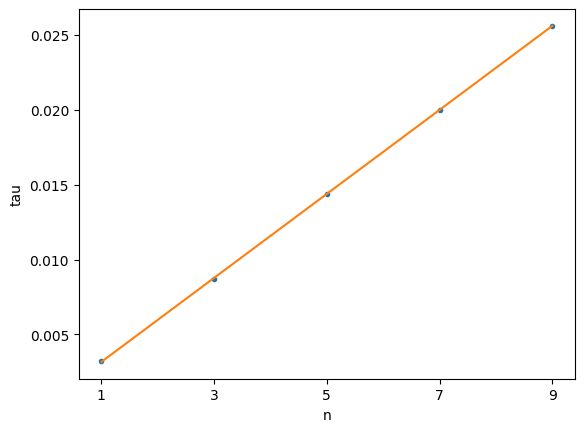

In [5]:
tau = 3.15e-3 #s
L = 1
data = '''
# n tau/ms
1 3.2
3 8.7
5 14.4
7 20.0
9 25.6
'''
n, tau = np.genfromtxt(data.splitlines()).T
tau *= 1e-3

fit = linregress(n, tau)
plt.plot(n, tau, '.')
plt.plot(n, fit.intercept + fit.slope * n)
plt.xticks(np.arange(1, 10, 2))
plt.xlabel('n')
plt.ylabel('tau')
v = L / fit.slope
print(f'Sound velocity in air {v:.0f} m/c')


# He

Sound velocity in Helium 947 m/c


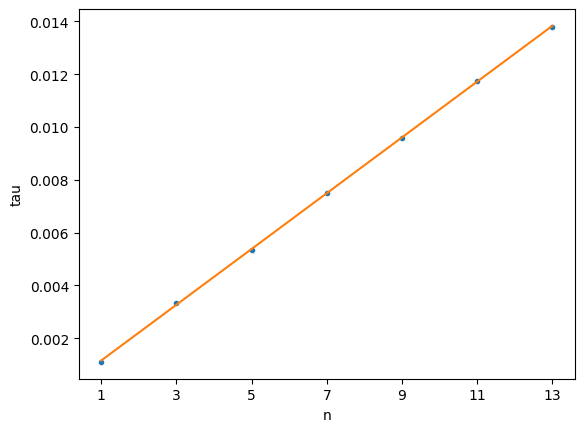

In [8]:
data = '''
# n tau/ms
1 1.1
3 3.35
5 5.35
7 7.5
9 9.6
11 11.75
13 13.8
'''
n, tau = np.genfromtxt(data.splitlines()).T
tau *= 1e-3

fit = linregress(n, tau)
plt.plot(n, tau, '.')
plt.plot(n, fit.intercept + fit.slope * n)
plt.xlabel('n')
plt.ylabel('tau')
plt.xticks(np.arange(1, 14, 2))
v = L / fit.slope
print(f'Sound velocity in Helium {v:.0f} m/c')

## CO2

Sound velocity in carbon Dioxide 288 m/c


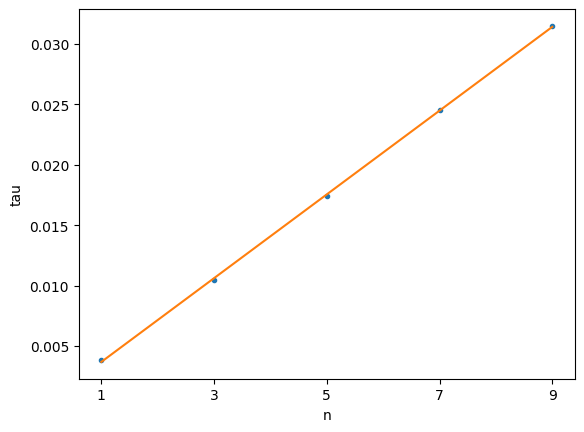

In [9]:
data = '''
# n tau/ms
1 3.85
3 10.45
5 17.45
7 24.5
9 31.5
'''
n, tau = np.genfromtxt(data.splitlines()).T
tau *= 1e-3

fit = linregress(n, tau)
plt.plot(n, tau, '.')
plt.plot(n, fit.intercept + fit.slope * n)
plt.xticks(np.arange(1, 10, 2))
plt.xlabel('n')
plt.ylabel('tau')
v = L / fit.slope
print(f'Sound velocity in carbon Dioxide {v:.0f} m/c')

## Resonance

$$
\frac{1}{f} = \frac{2 n L}{v}
$$
where $n$ - number of responce maximum, i.e first maximum $n=1$ happems when sound travels there and back again $2L$ length

180 Hz
360 Hz


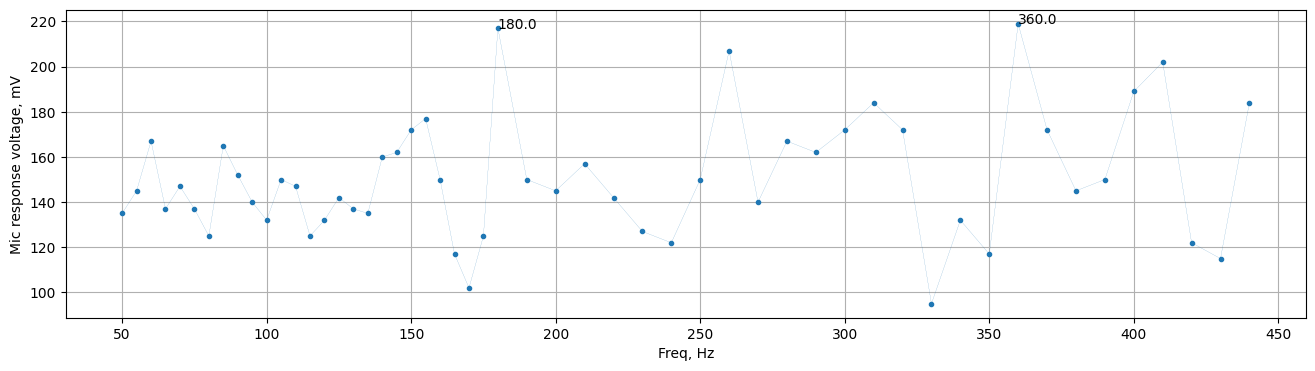

In [34]:
L = 1 #m
f = 4200 # Hz
data = '''
# freq/Hz Vmic/mV
50 135
55 145
60 167
65 137
70 147
75 137
80 125
#81 132
#82 157
#83 125
#84 137
85 165
#86 107
#87 172
#88 130
#89 130
90 152
95 140
100 132
105 150
110 147
115 125
120 132
125 142
130 137
135 135
140 160
145 162
150 172
155 177
160 150
165 117
170 102
#171 102
#172 122
#173 224
#174 257
175 125
180 217
#181 234
#182 150
190 150
200 145
210 157
220 142
230 127
240 122
250 150
260 207
270 140
280 167
290 162
300 172
310 184
320 172
330 95
340 132
350 117
360 219
370 172
380 145
390 150
400 189
410 202
420 122
430 115
440 184
'''.splitlines()

freq, v = np.genfromtxt(data).T
fig, ax = plt.subplots(1, 1, figsize=(16, 4))
plt.plot(freq, v, '.', ls='-', lw=0.1)
plt.xlabel('Freq, Hz')
plt.ylabel('Mic response voltage, mV')
for n, ix in enumerate(np.argsort(v)[-2:]):
  plt.annotate(freq[ix], (freq[ix], v[ix]))
  print(f'{freq[ix]:.0f} Hz')
  v = freq[ix] * L * n
  print
plt.grid()

In [36]:
v = 2 * L * 180
print(f'Resonance happened at {v:.0f} m/c')

Resonance happened at 360 m/c
